# Experiment 01B : Spatially Heterogenous Diffusion

**Drug Modeled** : Gefitinib

**Research Question** : How does spatial variation in extracellular collaged alter gefitinib diffusion and create spatial differences in drug exposure within tumor tissue?

## I. Heterogenous Diffusivity Field

This first test will use a synthetic collagen distribution, whereas accurate NSCLC distributions will be implemented with literature later on.

Our effective diffusivity will be:

$$D(x, y) = D_0 * g(x, y) $$

where $g(x, y)$ is a local hinderance factor:

$$ 0 < g(x, y) <= 1 $$

The value of $g(x, y)$ will be inversely proportional to the [Collagen] in one "tile" of the tumor domain.

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Tissue dimensions (cm)
Lx = 0.01
Ly = 0.02

# Number of cells
Nx = 51
Ny = 51

# Cell dimensions
dx = Lx / Nx
dy = Ly / Ny

# Cell-center coordinates
x = (np.arange(Nx) + 0.5) * dx
y = (np.arange(Ny) + 0.5) * dy

# Coordinate matrices
X, Y = np.meshgrid(x, y, indexing="ij")

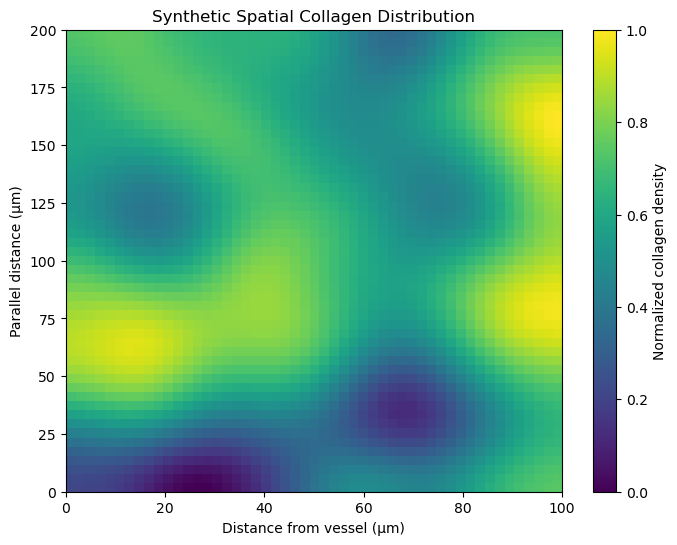

In [15]:
# ============================================================
# Experiment 01B-1: Synthetic spatial collagen field
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# ------------------------------------------------------------
# 1. Use existing physical domain
# ------------------------------------------------------------

# Use the original grid
Nx_coll = Nx
Ny_coll = Ny

x_coll = np.linspace(0, Lx, Nx_coll)
y_coll = np.linspace(0, Ly, Ny_coll)

# ------------------------------------------------------------
# 2. Generate spatially correlated random field
# ------------------------------------------------------------

rng = np.random.default_rng(42)

raw_field = rng.normal(0, 1, size=(Nx_coll, Ny_coll))

# Spatial correlation scale in grid cells
correlation_scale = 5

collagen_raw = gaussian_filter(
    raw_field,
    sigma=correlation_scale
)

# Normalize to [0, 1]
collagen = (
    collagen_raw - collagen_raw.min()
) / (
    collagen_raw.max() - collagen_raw.min()
)

# ------------------------------------------------------------
# 3. Display collagen field
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.imshow(
    collagen.T,
    origin="lower",
    extent=[0, Lx * 1e4, 0, Ly * 1e4],
    aspect="auto"
)

plt.colorbar(label="Normalized collagen density")
plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Parallel distance (μm)")
plt.title("Synthetic Spatial Collagen Distribution")

plt.show()

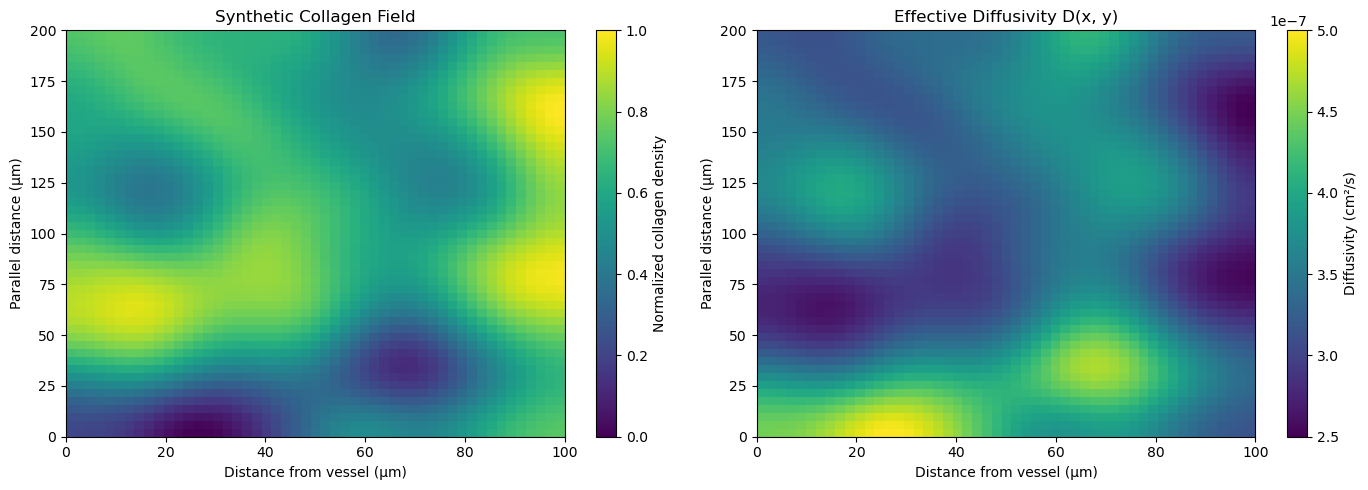

In [16]:
# ============================================================
# Experiment 01B-1: Collagen -> effective diffusivity
# ============================================================

# Baseline diffusivity
D0 = 5e-7  # cm^2/s

# Exploratory collagen hindrance strength
alpha_collagen = 0.50

# Hindrance factor
g_collagen = 1 - alpha_collagen * collagen

# Spatial diffusivity field
D_field = D0 * g_collagen

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Collagen
im1 = axes[0].imshow(
    collagen.T,
    origin="lower",
    extent=[0, Lx * 1e4, 0, Ly * 1e4],
    aspect="auto"
)

axes[0].set_title("Synthetic Collagen Field")
axes[0].set_xlabel("Distance from vessel (μm)")
axes[0].set_ylabel("Parallel distance (μm)")

plt.colorbar(
    im1,
    ax=axes[0],
    label="Normalized collagen density"
)

# Diffusivity
im2 = axes[1].imshow(
    D_field.T,
    origin="lower",
    extent=[0, Lx * 1e4, 0, Ly * 1e4],
    aspect="auto"
)

axes[1].set_title("Effective Diffusivity D(x, y)")
axes[1].set_xlabel("Distance from vessel (μm)")
axes[1].set_ylabel("Parallel distance (μm)")

plt.colorbar(
    im2,
    ax=axes[1],
    label="Diffusivity (cm²/s)"
)

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# Experiment 01B-1: Field statistics
# ============================================================

print("COLLAGEN FIELD")
print("-" * 40)
print(f"Minimum: {collagen.min():.4f}")
print(f"Maximum: {collagen.max():.4f}")
print(f"Mean:    {collagen.mean():.4f}")
print(f"SD:      {collagen.std():.4f}")

print("\nHINDRANCE FACTOR")
print("-" * 40)
print(f"Minimum: {g_collagen.min():.4f}")
print(f"Maximum: {g_collagen.max():.4f}")
print(f"Mean:    {g_collagen.mean():.4f}")

print("\nDIFFUSIVITY FIELD")
print("-" * 40)
print(f"Minimum: {D_field.min():.4e} cm^2/s")
print(f"Maximum: {D_field.max():.4e} cm^2/s")
print(f"Mean:    {D_field.mean():.4e} cm^2/s")
print(f"SD:      {D_field.std():.4e} cm^2/s")

COLLAGEN FIELD
----------------------------------------
Minimum: 0.0000
Maximum: 1.0000
Mean:    0.6021
SD:      0.1932

HINDRANCE FACTOR
----------------------------------------
Minimum: 0.5000
Maximum: 1.0000
Mean:    0.6989

DIFFUSIVITY FIELD
----------------------------------------
Minimum: 2.5000e-07 cm^2/s
Maximum: 5.0000e-07 cm^2/s
Mean:    3.4946e-07 cm^2/s
SD:      4.8301e-08 cm^2/s


## II. Variable Diffusivity Solver

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Experiment 01B: Variable diffusivity solver

# Baseline diffusivity
D = 5e-7  # cm^2/s

# Vascular exchange coefficient
Pv = 2e-5  # cm/s

# Normalized vascular concentration
Cv = 1.0

# Drug initially absent from tissue
C = np.zeros((Nx, Ny))

# Simulation settings
dt = 0.01
T = 60
Nt = int(T / dt)

save_times = [0, 1, 5, 15, 30, 60]

In [19]:
def diffusion_step_vascular(C, D, Pv, Cv, dx, dy, dt):

    Nx, Ny = C.shape

    # Allow D to be either a scalar or a spatial field
    D = np.broadcast_to(np.asarray(D, dtype=float), C.shape)

    # ==========================================================
    # X-DIRECTION FLUXES
    # ==========================================================

    Fx = np.zeros((Nx + 1, Ny))

    # Harmonic mean diffusivity at internal x-faces
    D_x_face = (
        2 * D[:-1, :] * D[1:, :]
        / (D[:-1, :] + D[1:, :])
    )

    Fx[1:-1, :] = -D_x_face * (
        C[1:, :] - C[:-1, :]
    ) / dx

    # Vascular boundary at x = 0
    # Effective permeability accounting for half-cell diffusion
    D_vessel = D[0, :]

    P_eff = 1 / (
        1 / Pv + dx / (2 * D_vessel)
    )

    Fx[0, :] = P_eff * (Cv - C[0, :])

    # Distal boundary: zero flux
    Fx[-1, :] = 0


    # ==========================================================
    # Y-DIRECTION FLUXES (PERIODIC)
    # ==========================================================

    Fy = np.zeros((Nx, Ny + 1))

    # Harmonic mean diffusivity at internal y-faces
    D_y_face = (
        2 * D[:, :-1] * D[:, 1:]
        / (D[:, :-1] + D[:, 1:])
    )

    Fy[:, 1:-1] = -D_y_face * (
        C[:, 1:] - C[:, :-1]
    ) / dy

    # Periodic interface: last cell <-> first cell
    D_y_periodic = (
        2 * D[:, -1] * D[:, 0]
        / (D[:, -1] + D[:, 0])
    )

    periodic_flux = -D_y_periodic * (
        C[:, 0] - C[:, -1]
    ) / dy

    Fy[:, 0] = periodic_flux
    Fy[:, -1] = periodic_flux


    # ==========================================================
    # FLUX DIVERGENCE
    # ==========================================================

    divergence_x = (
        Fx[1:, :] - Fx[:-1, :]
    ) / dx

    divergence_y = (
        Fy[:, 1:] - Fy[:, :-1]
    ) / dy

    divergence = divergence_x + divergence_y


    # ==========================================================
    # CONCENTRATION UPDATE
    # ==========================================================

    C_new = C - dt * divergence

    return C_new

In [20]:
# ============================================================
# 01B-2: Uniform diffusivity regression test
# ============================================================

# Constant diffusivity as a scalar
D_scalar = D0

# Same diffusivity represented as a spatial field
D_uniform_field = np.full_like(C, D0, dtype=float)

# One update using scalar D
C_scalar_test = diffusion_step_vascular(
    C, D_scalar, Pv, Cv, dx, dy, dt
)

# One update using uniform array D
C_field_test = diffusion_step_vascular(
    C, D_uniform_field, Pv, Cv, dx, dy, dt
)

difference = np.max(
    np.abs(C_scalar_test - C_field_test)
)

print("Uniform diffusivity regression test")
print("-" * 45)
print(f"Maximum difference: {difference:.6e}")

if difference < 1e-12:
    print("PASS: scalar and uniform-field diffusivity agree.")
else:
    print("CHECK: discrepancy detected.")

Uniform diffusivity regression test
---------------------------------------------
Maximum difference: 0.000000e+00
PASS: scalar and uniform-field diffusivity agree.


In [21]:
# ============================================================
# Experiment 01B-2: Heterogeneous diffusion test
# ============================================================

# Simulation parameters
Pv_test = 1e-5
Cv_test = 1.0
t_end = 60.0

# Use existing timestep
dt_test = dt

n_steps = int(t_end / dt_test)

# Initialize concentration
C_hetero = np.zeros((Nx, Ny), dtype=float)

# Tracking
times = []
mass_history = []
influx_history = []

cumulative_influx = 0.0

# Cell area
cell_area = dx * dy

# Vascular effective permeability
D_vessel = D_field[0, :]

P_eff = 1 / (
    1 / Pv_test + dx / (2 * D_vessel)
)

# ============================================================
# Time integration
# ============================================================

for step in range(n_steps):

    # Vascular influx before the update
    influx_rate = np.sum(
        P_eff * (Cv_test - C_hetero[0, :])
    ) * dy

    # Advance concentration
    C_hetero = diffusion_step_vascular(
        C_hetero,
        D_field,
        Pv_test,
        Cv_test,
        dx,
        dy,
        dt_test
    )

    # Accumulate incoming mass
    cumulative_influx += influx_rate * dt_test

    # Record results
    t = (step + 1) * dt_test

    times.append(t)

    mass_history.append(
        np.sum(C_hetero) * cell_area
    )

    influx_history.append(cumulative_influx)


times = np.array(times)
mass_history = np.array(mass_history)
influx_history = np.array(influx_history)

# ============================================================
# Conservation error
# ============================================================

relative_error = np.abs(
    mass_history - influx_history
) / np.maximum(
    np.abs(influx_history), 1e-15
)

print("HETEROGENEOUS DIFFUSION TEST")
print("-" * 50)
print(f"Final time: {times[-1]:.2f} s")
print(f"Maximum concentration: {C_hetero.max():.6e}")
print(f"Minimum concentration: {C_hetero.min():.6e}")
print(f"Final tissue mass: {mass_history[-1]:.6e}")
print(f"Total vascular influx: {influx_history[-1]:.6e}")
print(f"Final relative conservation error: {relative_error[-1]:.6e}")
print(f"Maximum conservation error: {relative_error.max():.6e}")

HETEROGENEOUS DIFFUSION TEST
--------------------------------------------------
Final time: 60.00 s
Maximum concentration: 1.389157e-01
Minimum concentration: 1.732282e-02
Final tissue mass: 1.090088e-05
Total vascular influx: 1.090088e-05
Final relative conservation error: 2.331095e-15
Maximum conservation error: 4.412891e-15


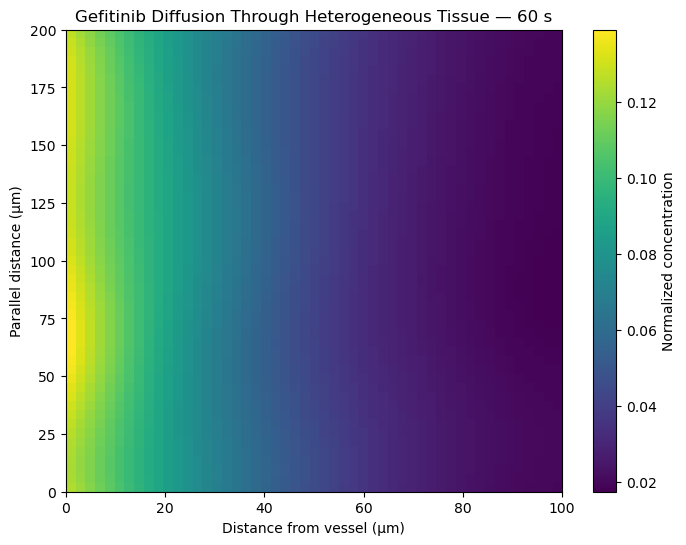

In [22]:
plt.figure(figsize=(8, 6))

plt.imshow(
    C_hetero.T,
    origin="lower",
    extent=[0, Lx * 1e4, 0, Ly * 1e4],
    aspect="auto"
)

plt.colorbar(label="Normalized concentration")
plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Parallel distance (μm)")
plt.title("Gefitinib Diffusion Through Heterogeneous Tissue — 60 s")

plt.show()

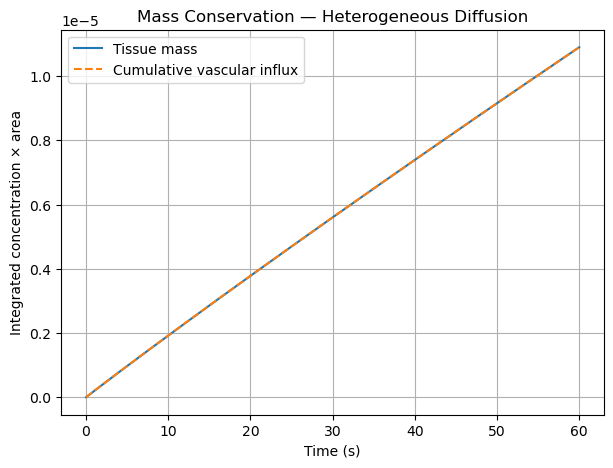

In [23]:
plt.figure(figsize=(7, 5))

plt.plot(times, mass_history, label="Tissue mass")
plt.plot(times, influx_history, "--", label="Cumulative vascular influx")

plt.xlabel("Time (s)")
plt.ylabel("Integrated concentration × area")
plt.title("Mass Conservation — Heterogeneous Diffusion")
plt.legend()
plt.grid(True)

plt.show()

In [24]:
# ============================================================
# Experiment 01B-2: Mean-matched heterogeneous vs uniform control
# ============================================================

D_mean = np.mean(D_field)

D_uniform_control = np.full_like(
    D_field,
    D_mean,
    dtype=float
)

Pv_test = 1e-5
Cv_test = 1.0
t_end = 60.0
dt_test = dt
n_steps = int(t_end / dt_test)

cell_area = dx * dy


def run_transport_comparison(D_sim, Pv, Cv, n_steps, dt):

    C_sim = np.zeros((Nx, Ny), dtype=float)

    mass_history = []
    influx_history = []
    cumulative_influx = 0.0

    # Effective vascular exchange for each y location
    D_vessel = D_sim[0, :]

    P_eff = 1 / (
        1 / Pv + dx / (2 * D_vessel)
    )

    for step in range(n_steps):

        # Calculate vascular influx
        influx_rate = np.sum(
            P_eff * (Cv - C_sim[0, :])
        ) * dy

        # Advance solution
        C_sim = diffusion_step_vascular(
            C_sim,
            D_sim,
            Pv,
            Cv,
            dx,
            dy,
            dt
        )

        cumulative_influx += influx_rate * dt

        # Record integrated mass
        mass_history.append(
            np.sum(C_sim) * cell_area
        )

        influx_history.append(cumulative_influx)

    return (
        C_sim,
        np.array(mass_history),
        np.array(influx_history)
    )


# ------------------------------------------------------------
# Run heterogeneous tissue
# ------------------------------------------------------------

C_hetero_final, mass_hetero, influx_hetero = (
    run_transport_comparison(
        D_field,
        Pv_test,
        Cv_test,
        n_steps,
        dt_test
    )
)

# ------------------------------------------------------------
# Run mean-matched uniform tissue
# ------------------------------------------------------------

C_uniform_final, mass_uniform, influx_uniform = (
    run_transport_comparison(
        D_uniform_control,
        Pv_test,
        Cv_test,
        n_steps,
        dt_test
    )
)

print("MEAN-MATCHED COMPARISON")
print("-" * 60)
print(f"Mean heterogeneous D: {D_mean:.6e} cm^2/s")
print(f"Uniform control D:   {D_uniform_control.mean():.6e} cm^2/s")

print("\nHeterogeneous tissue")
print(f"Final mass: {mass_hetero[-1]:.6e}")
print(f"Final influx: {influx_hetero[-1]:.6e}")

print("\nUniform control")
print(f"Final mass: {mass_uniform[-1]:.6e}")
print(f"Final influx: {influx_uniform[-1]:.6e}")

MEAN-MATCHED COMPARISON
------------------------------------------------------------
Mean heterogeneous D: 3.494631e-07 cm^2/s
Uniform control D:   3.494631e-07 cm^2/s

Heterogeneous tissue
Final mass: 1.090088e-05
Final influx: 1.090088e-05

Uniform control
Final mass: 1.091206e-05
Final influx: 1.091206e-05


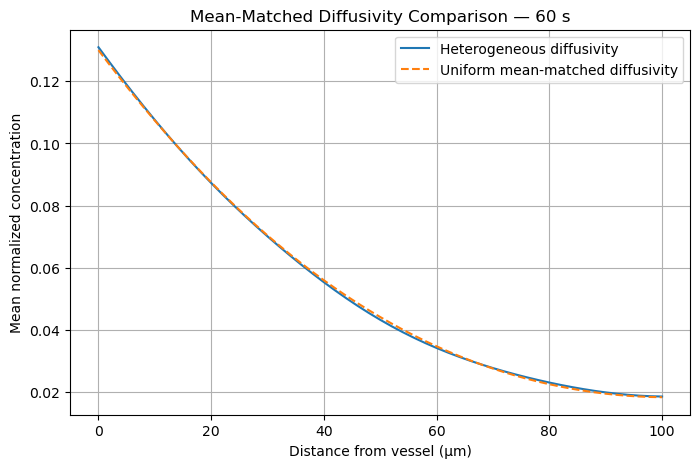

In [25]:
# ============================================================
# Mean concentration profiles
# ============================================================

C_hetero_profile = C_hetero_final.mean(axis=1)
C_uniform_profile = C_uniform_final.mean(axis=1)

x_um = x_coll * 1e4

plt.figure(figsize=(8, 5))

plt.plot(
    x_um,
    C_hetero_profile,
    label="Heterogeneous diffusivity"
)

plt.plot(
    x_um,
    C_uniform_profile,
    "--",
    label="Uniform mean-matched diffusivity"
)

plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Mean normalized concentration")
plt.title("Mean-Matched Diffusivity Comparison — 60 s")
plt.legend()
plt.grid(True)

plt.show()

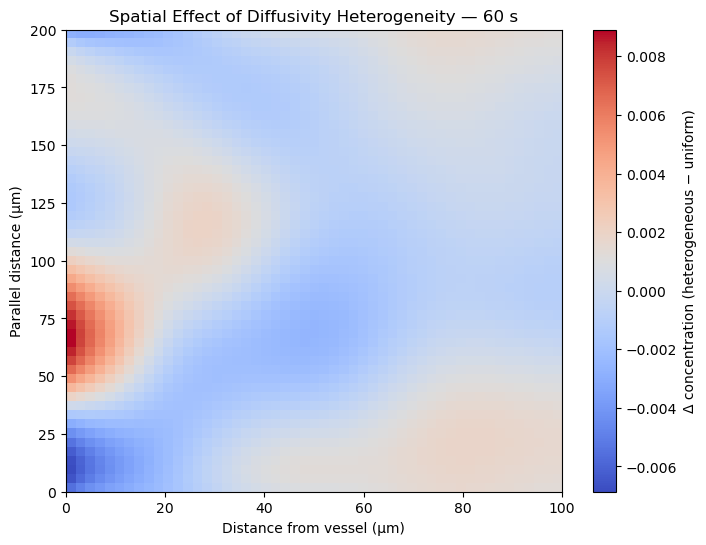

In [26]:
# ============================================================
# Spatial difference between heterogeneous and uniform control
# ============================================================

C_difference = C_hetero_final - C_uniform_final

plt.figure(figsize=(8, 6))

plt.imshow(
    C_difference.T,
    origin="lower",
    extent=[0, Lx * 1e4, 0, Ly * 1e4],
    aspect="auto",
    cmap="coolwarm"
)

plt.colorbar(label="Δ concentration (heterogeneous − uniform)")
plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Parallel distance (μm)")
plt.title("Spatial Effect of Diffusivity Heterogeneity — 60 s")

plt.show()

In [27]:
# ============================================================
# Quantitative comparison
# ============================================================

mean_hetero = C_hetero_final.mean()
mean_uniform = C_uniform_final.mean()

distal_hetero = C_hetero_final[-1, :].mean()
distal_uniform = C_uniform_final[-1, :].mean()

max_abs_difference = np.max(np.abs(C_difference))

rmse = np.sqrt(
    np.mean(C_difference**2)
)

relative_difference = (
    np.linalg.norm(C_difference)
    / np.linalg.norm(C_uniform_final)
) * 100

print("HETEROGENEITY EFFECT")
print("-" * 55)
print(f"Mean concentration — heterogeneous: {mean_hetero:.6e}")
print(f"Mean concentration — uniform:     {mean_uniform:.6e}")
print(f"Distal concentration — hetero:   {distal_hetero:.6e}")
print(f"Distal concentration — uniform:   {distal_uniform:.6e}")
print(f"Maximum absolute difference:      {max_abs_difference:.6e}")
print(f"RMSE:                            {rmse:.6e}")
print(f"Relative field difference:         {relative_difference:.4f}%")

HETEROGENEITY EFFECT
-------------------------------------------------------
Mean concentration — heterogeneous: 5.450441e-02
Mean concentration — uniform:     5.456030e-02
Distal concentration — hetero:   1.855046e-02
Distal concentration — uniform:   1.832517e-02
Maximum absolute difference:      8.907917e-03
RMSE:                            1.570593e-03
Relative field difference:         2.4508%


## III. Boundary-Matched Control

**Research Question** : Does interior spatial heterogenity in diffusivity change the drug concentration distribution when vascular exchange is held constant?

We will compare:
* Case A - Heterogenous : original $D_{field}$ throughout the tissue
* Case B - Uniform control : uniform diffusivity throughout the tissue, set to the mean of $D_{field}$
* Boundary matching : both simulations use the same fixed vascular effective permeability, calculated from the same vessel-side diffusivity

In [28]:
# ============================================================
# 01B-2C: Boundary-matched transport solver
# ============================================================

def diffusion_step_fixed_boundary(
    C, D, P_eff_fixed, Cv, dx, dy, dt
):
    Nx, Ny = C.shape

    # -----------------------------
    # X-direction fluxes
    # -----------------------------
    Fx = np.zeros((Nx + 1, Ny), dtype=float)

    # Harmonic diffusivity at internal faces
    D_x_face = (
        2 * D[:-1, :] * D[1:, :]
        / (D[:-1, :] + D[1:, :] + 1e-30)
    )

    Fx[1:-1, :] = (
        -D_x_face * (C[1:, :] - C[:-1, :]) / dx
    )

    # Identical vascular boundary for both cases
    Fx[0, :] = P_eff_fixed * (Cv - C[0, :])

    # Distal zero-flux boundary
    Fx[-1, :] = 0.0

    # -----------------------------
    # Y-direction periodic fluxes
    # -----------------------------
    Fy = np.zeros((Nx, Ny + 1), dtype=float)

    D_y_face = (
        2 * D[:, :-1] * D[:, 1:]
        / (D[:, :-1] + D[:, 1:] + 1e-30)
    )

    Fy[:, 1:-1] = (
        -D_y_face * (C[:, 1:] - C[:, :-1]) / dy
    )

    # Periodic last-to-first connection
    D_periodic = (
        2 * D[:, 0] * D[:, -1]
        / (D[:, 0] + D[:, -1] + 1e-30)
    )

    periodic_flux = (
        -D_periodic * (C[:, 0] - C[:, -1]) / dy
    )

    Fy[:, 0] = periodic_flux
    Fy[:, -1] = periodic_flux

    # -----------------------------
    # Conservative divergence
    # -----------------------------
    divergence_x = (Fx[1:, :] - Fx[:-1, :]) / dx
    divergence_y = (Fy[:, 1:] - Fy[:, :-1]) / dy

    C_new = C - dt * (divergence_x + divergence_y)

    return C_new

In [29]:
# ============================================================
# 01B-2C: Define shared parameters
# ============================================================

Pv_test = 1e-5
Cv_test = 1.0
t_end = 60.0
dt_test = dt

n_steps = int(t_end / dt_test)
cell_area = dx * dy

# Mean vessel-facing diffusivity
D_boundary_fixed = np.mean(D_field[0, :])

# Calculate vascular exchange coefficient ONCE
P_eff_fixed = 1 / (
    1 / Pv_test + dx / (2 * D_boundary_fixed)
)

# Uniform mean-matched diffusivity
D_mean = np.mean(D_field)

D_uniform = np.full_like(
    D_field, D_mean, dtype=float
)

print("BOUNDARY-MATCHED PARAMETERS")
print("-" * 50)
print(f"Pv:                   {Pv_test:.6e} cm/s")
print(f"Vascular concentration: {Cv_test}")
print(f"Boundary diffusivity:  {D_boundary_fixed:.6e} cm^2/s")
print(f"Fixed effective P:     {P_eff_fixed:.6e} cm/s")
print(f"Mean tissue D:         {D_mean:.6e} cm^2/s")
print(f"dt:                    {dt_test:.6e} s")
print(f"Steps:                  {n_steps}")

BOUNDARY-MATCHED PARAMETERS
--------------------------------------------------
Pv:                   1.000000e-05 cm/s
Vascular concentration: 1.0
Boundary diffusivity:  3.426710e-07 cm^2/s
Fixed effective P:     9.971471e-06 cm/s
Mean tissue D:         3.494631e-07 cm^2/s
dt:                    1.000000e-02 s
Steps:                  6000


In [30]:
# ============================================================
# 01B-2C: Simulation function
# ============================================================

def run_fixed_boundary_case(D_sim):

    C_sim = np.zeros((Nx, Ny), dtype=float)

    mass_history = []
    influx_history = []

    cumulative_influx = 0.0

    for step in range(n_steps):

        # Boundary influx using the SAME P_eff in both cases
        influx_rate = np.sum(
            P_eff_fixed * (Cv_test - C_sim[0, :])
        ) * dy

        # Advance simulation
        C_sim = diffusion_step_fixed_boundary(
            C_sim,
            D_sim,
            P_eff_fixed,
            Cv_test,
            dx,
            dy,
            dt_test
        )

        cumulative_influx += influx_rate * dt_test

        mass_history.append(
            np.sum(C_sim) * cell_area
        )

        influx_history.append(cumulative_influx)

    return (
        C_sim,
        np.array(mass_history),
        np.array(influx_history)
    )


# Heterogeneous case
C_hetero_BM, mass_hetero_BM, influx_hetero_BM = (
    run_fixed_boundary_case(D_field)
)

# Uniform mean-matched control
C_uniform_BM, mass_uniform_BM, influx_uniform_BM = (
    run_fixed_boundary_case(D_uniform)
)

print("Both simulations completed.")

Both simulations completed.


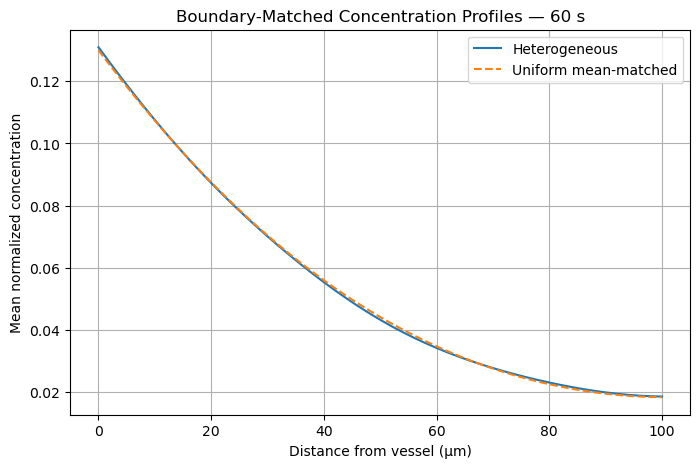

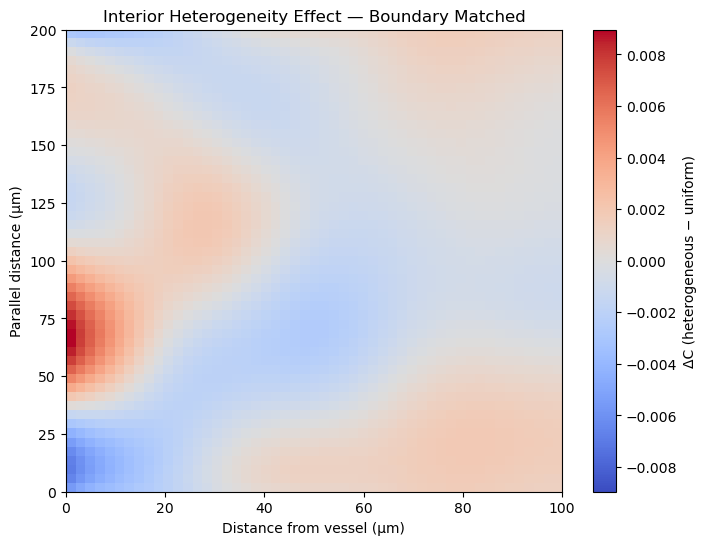

In [31]:
# ============================================================
# 01B-2C: Comparison plots
# ============================================================

C_diff_BM = C_hetero_BM - C_uniform_BM

x_um = x_coll * 1e4

# Mean profiles
plt.figure(figsize=(8, 5))

plt.plot(
    x_um,
    C_hetero_BM.mean(axis=1),
    label="Heterogeneous"
)

plt.plot(
    x_um,
    C_uniform_BM.mean(axis=1),
    "--",
    label="Uniform mean-matched"
)

plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Mean normalized concentration")
plt.title("Boundary-Matched Concentration Profiles — 60 s")
plt.legend()
plt.grid(True)
plt.show()


# Difference field
plt.figure(figsize=(8, 6))

limit = np.max(np.abs(C_diff_BM))

plt.imshow(
    C_diff_BM.T,
    origin="lower",
    extent=[0, Lx * 1e4, 0, Ly * 1e4],
    aspect="auto",
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)

plt.colorbar(label="ΔC (heterogeneous − uniform)")
plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Parallel distance (μm)")
plt.title("Interior Heterogeneity Effect — Boundary Matched")
plt.show()

In [32]:
# ============================================================
# 01B-2C: Final comparison metrics
# ============================================================

diff = C_hetero_BM - C_uniform_BM

relative_field_difference = (
    np.linalg.norm(diff)
    / max(np.linalg.norm(C_uniform_BM), 1e-15)
) * 100

rmse = np.sqrt(np.mean(diff**2))
max_difference = np.max(np.abs(diff))

mean_hetero = C_hetero_BM.mean()
mean_uniform = C_uniform_BM.mean()

distal_hetero = C_hetero_BM[-1, :].mean()
distal_uniform = C_uniform_BM[-1, :].mean()

error_hetero = (
    abs(mass_hetero_BM[-1] - influx_hetero_BM[-1])
    / max(abs(influx_hetero_BM[-1]), 1e-15)
)

error_uniform = (
    abs(mass_uniform_BM[-1] - influx_uniform_BM[-1])
    / max(abs(influx_uniform_BM[-1]), 1e-15)
)

print("=" * 60)
print("BOUNDARY-MATCHED HETEROGENEITY RESULTS")
print("=" * 60)

print(f"Mean concentration (heterogeneous): {mean_hetero:.6e}")
print(f"Mean concentration (uniform):      {mean_uniform:.6e}")

print(f"\nDistal concentration (hetero):    {distal_hetero:.6e}")
print(f"Distal concentration (uniform):    {distal_uniform:.6e}")

print(f"\nRMSE:                              {rmse:.6e}")
print(f"Maximum absolute difference:        {max_difference:.6e}")
print(f"Relative field difference:         {relative_field_difference:.4f}%")

print(f"\nMass conservation error (hetero):  {error_hetero:.6e}")
print(f"Mass conservation error (uniform): {error_uniform:.6e}")

print(f"\nMinimum heterogeneous concentration: {C_hetero_BM.min():.6e}")
print(f"Minimum uniform concentration:     {C_uniform_BM.min():.6e}")

BOUNDARY-MATCHED HETEROGENEITY RESULTS
Mean concentration (heterogeneous): 5.450654e-02
Mean concentration (uniform):      5.455754e-02

Distal concentration (hetero):    1.855098e-02
Distal concentration (uniform):    1.832422e-02

RMSE:                              1.574090e-03
Maximum absolute difference:        8.957761e-03
Relative field difference:         2.4564%

Mass conservation error (hetero):  2.486404e-15
Mass conservation error (uniform): 1.242040e-15

Minimum heterogeneous concentration: 1.732439e-02
Minimum uniform concentration:     1.832422e-02
